#  Machine Learning — Sesioni 4

#### 1. Metrikat: Accuracy · Precision · Recall · F1
#### 2. Overfitting & Underfitting

**Dataseti:** `employees_churn.csv`


##  Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split, learning_curve
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)
from sklearn.pipeline import make_pipeline


df = pd.read_csv('../data/employees_churn.csv')


## Ritrajno modelin

In [2]:
X = pd.get_dummies(df[['Mosha','Bonus','vite_pune','Departamenti']], drop_first=True)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
y_pred = model.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')


TN=24, FP=11, FN=12, TP=23


##  Metrikat me dorë

In [3]:
accuracy_manual  = (tp + tn) / (tp + tn + fp + fn)
precision_manual = tp / (tp + fp) if (tp + fp) > 0 else 0
recall_manual    = tp / (tp + fn) if (tp + fn) > 0 else 0
f1_manual = 2*precision_manual*recall_manual/(precision_manual+recall_manual) if (precision_manual+recall_manual)>0 else 0

print('Me dorë:', accuracy_manual, precision_manual, recall_manual, f1_manual)
print('Me sklearn:', accuracy_score(y_test,y_pred), precision_score(y_test,y_pred),
      recall_score(y_test,y_pred), f1_score(y_test,y_pred))


Me dorë: 0.6714285714285714 0.6764705882352942 0.6571428571428571 0.6666666666666666
Me sklearn: 0.6714285714285714 0.6764705882352942 0.6571428571428571 0.6666666666666666


## classification_report

In [4]:
print(classification_report(y_test, y_pred, target_names=['Qëndron (0)', 'Largohet (1)']))


              precision    recall  f1-score   support

 Qëndron (0)       0.67      0.69      0.68        35
Largohet (1)       0.68      0.66      0.67        35

    accuracy                           0.67        70
   macro avg       0.67      0.67      0.67        70
weighted avg       0.67      0.67      0.67        70



Modeli ka një Accuracy prej 67%, ndërsa Precision, Recall dhe F1-score janë rreth 0.67 për të dy klasat. Kjo tregon se modeli ka performancë të ngjashme për punonjësit që Qëndrojnë dhe ata që Largohen, pa favorizuar njërën klasë ndaj tjetrës.

In [5]:
df_small = pd.concat([
    df[df["churn"] == 1],
    df[df["churn"] == 0].sample(30, random_state=42)
])

X = pd.get_dummies(df_small[['Mosha','Bonus','vite_pune','Departamenti']], drop_first=True)
y = df_small['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
y_pred = model.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')

TN=0, FP=6, FN=0, TP=36


Modeli parashikoi pothuajse te gjithe punonjesit si "Largohet". Nuk humbi asnje rast largimi (Recall = 100%), por krijoi disa False Positives. Ky eshte nje rast ku preferojme Recall ndaj Precision.

In [6]:
df_imbalanced = pd.concat([
    df[df["churn"] == 0],
    df[df["churn"] == 1].sample(20, random_state=42)
])

X = pd.get_dummies(df_imbalanced[['Mosha','Bonus','vite_pune','Departamenti']], drop_first=True)
y = df_imbalanced['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
y_pred = model.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')

TN=35, FP=0, FN=4, TP=0


Modeli parashikoi pothuajse te gjithe punonjesit si "Qendron". Edhe pse Accuracy mund te jete e larte, ai nuk identifikoi asnje punonjes qe largohet (TP = 0). Ne kete rast, Recall eshte metrika me e rendesishme

## Overfitting & Underfitting


###  Modeli A — i thjeshtë

In [7]:
X_A = df[['Mosha']]
y = df['Paga']

X_tr, X_te, y_tr, y_te = train_test_split(X_A, y, test_size=0.2, random_state=42)
model_A = LinearRegression().fit(X_tr, y_tr)
tr_A, te_A = model_A.score(X_tr, y_tr), model_A.score(X_te, y_te)
print(f'A → train R²={tr_A:.3f}, test R²={te_A:.3f}, diff={tr_A-te_A:+.3f}')

A → train R²=0.436, test R²=0.381, diff=+0.055


### Modeli B — i balancuar

In [8]:
X_B = pd.get_dummies(df[['Mosha','Bonus','vite_pune','Departamenti']], drop_first=True)
X_tr, X_te, y_tr, y_te = train_test_split(X_B, y, test_size=0.2, random_state=42)
model_B = LinearRegression().fit(X_tr, y_tr)
tr_B, te_B = model_B.score(X_tr, y_tr), model_B.score(X_te, y_te)
print(f'B → train R²={tr_B:.3f}, test R²={te_B:.3f}, diff={tr_B-te_B:+.3f}')


B → train R²=0.850, test R²=0.764, diff=+0.086


### Modeli C — polinom grad 3 (rrezik overfit)

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(X_B, y, test_size=0.2, random_state=42)
model_C = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), LinearRegression())
model_C.fit(X_tr, y_tr)
tr_C, te_C = model_C.score(X_tr, y_tr), model_C.score(X_te, y_te)
print(f'C → train R²={tr_C:.3f}, test R²={te_C:.3f}, diff={tr_C-te_C:+.3f}')


C → train R²=0.813, test R²=0.746, diff=+0.067


## 📉 Learning Curve

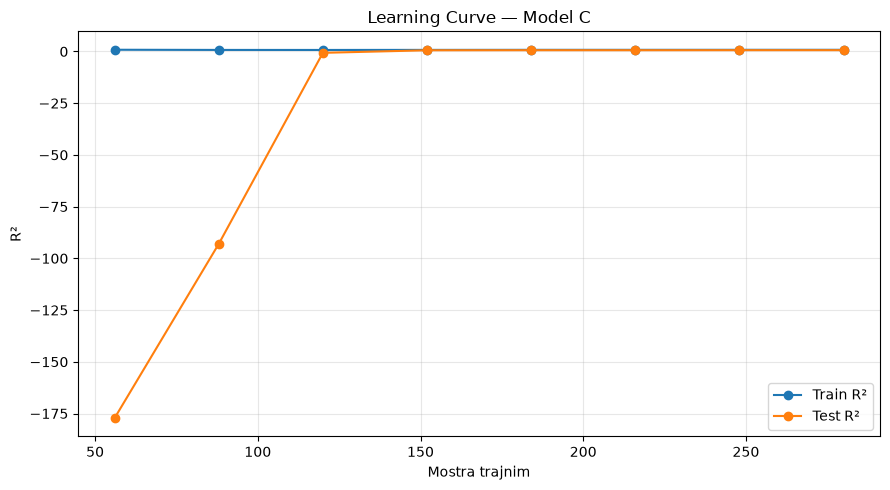

[ 56  88 120 152 184 216 248 280]
Train:
[[0.83529743 0.83607917 0.83607917 0.83607917 0.83607917]
 [0.84872028 0.81516872 0.69508577 0.69508577 0.69508577]
 [0.84579742 0.81052267 0.67396006 0.67396006 0.67396006]
 [0.8457051  0.82140629 0.69295606 0.73997833 0.73997833]
 [0.85479757 0.83347867 0.74169592 0.77545946 0.77545946]
 [0.84709879 0.82547124 0.7450272  0.78462254 0.7936407 ]
 [0.85297265 0.83206291 0.76404316 0.79442934 0.80267621]
 [0.85564221 0.83686462 0.77494492 0.80220546 0.79197691]]
Test:
[[ 1.40618544e-01 -2.21058575e+02 -4.44873921e+01 -3.60006369e+02
  -2.60640847e+02]
 [ 3.01649493e-01 -1.44977739e+00 -8.10346277e+01 -2.49178141e+02
  -1.33748957e+02]
 [ 2.59966707e-01  4.77823830e-01  1.25027132e-01 -1.04415292e+00
  -3.07891475e+00]
 [ 1.74566878e-01  5.28328661e-01  7.71881235e-01  7.39197183e-01
   7.10805200e-01]
 [ 1.50549366e-01  5.51925235e-01  8.18433956e-01  7.86781206e-01
   7.87472140e-01]
 [ 5.94542210e-02  5.69761861e-01  8.26812651e-01  8.03197611e-

In [10]:
sizes, tr_scores, te_scores = learning_curve(
    model_C, X_B, y, train_sizes=np.linspace(0.2,1,8), cv=5, scoring='r2')

plt.figure(figsize=(9,5))
plt.plot(sizes, tr_scores.mean(1), 'o-', label='Train R²')
plt.plot(sizes, te_scores.mean(1), 'o-', label='Test R²')
plt.xlabel('Mostra trajnim'); plt.ylabel('R²'); plt.title('Learning Curve — Model C')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print(sizes)

print("Train:")
print(tr_scores)

print("Test:")
print(te_scores)


### Ushtrimi 1 — A po bëhet modeli shumë kompleks?

Trajnoni tre modele Logistic Regression me:
1. pa Polynomial Features
2. Polynomial Features (degree = 2)
3. Polynomial Features (degree = 5)

Për secilin model:
1. Llogaritni Accuracy në Training Set.
2. Llogaritni Accuracy në Test Set.
3. Krahasoni rezultatet. Cili model duket se është: Underfitting? I balancuar? Overfitting?

### Ushtrimi 2 — Cili model performon më mirë?

Trajnoni dhe krahasoni këto modele:
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

Për secilin model:
1. Trajnoni modelin.
2. Llogaritni Accuracy, Precision dhe Recall
3. Shfaqni Confusion Matrix.
4. Cili model performon më mirë? A ka ndonjë model që bën më pak gabime?